# DPM-Solver / DPM-Solver++：先训练模型，再比较 ODE 与 SDE 求解器

本 notebook 先在二维八模态高斯混合上训练数据预测网络 $D_\theta(x_\lambda,\lambda)$，再把**同一个训练模型**交给不同求解器。解析 GMM 只用于验证参数化公式、一步等价关系、随机积分方差，以及评估网络是否学到了真实后验均值。

| 阶段 | 实验内容 |
|---|---|
| 模型训练 | 训练数据预测网络，并与解析 Tweedie 后验 $D(x,\lambda)$ 比较 |
| 解析单元测试 | Score / $\epsilon$ / $D$ 转换，一阶 DDIM 等价性，Itô 积分方差 |
| 学习模型 + ODE | Euler、Heun、DPM-Solver++1、2S、2M 的误差、NFE、MMD 和生成图 |
| 学习模型 + SDE | SDE-DPM-Solver++1、2M 与确定性 2M 在相同 NFE 下的 MMD 和样本图 |

这种结构把两类误差分开：600 步 RK4 与少步求解器的差异是**数值离散误差**；所有方法相对真实八模态分布的偏差还包含**模型误差**。

> 运行环境：`conda activate pytorch`。代码自动使用 CUDA，随机种子固定为 42。

## 1. VP 扩散与 logSNR 时间

使用半对数信噪比

$$
\lambda=\log\frac{\alpha}{\sigma},
\qquad \alpha_\lambda^2+\sigma_\lambda^2=1,
$$

并直接参数化为

$$
\alpha_\lambda=\sqrt{\operatorname{sigmoid}(2\lambda)},
\qquad
\sigma_\lambda=\sqrt{\operatorname{sigmoid}(-2\lambda)}.
$$

正向扰动为

$$
x_\lambda=\alpha_\lambda x_0+\sigma_\lambda\epsilon,
\qquad \epsilon\sim\mathcal N(0,I).
$$

反向生成从低信噪比 $\lambda_{\min}$ 积分到高信噪比 $\lambda_{\max}$。在 logSNR 空间均匀划分，可以让求解器直接利用扩散半线性结构。

In [1]:
from pathlib import Path
import csv
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float64
SEED = 42
OUTPUT_DIR = Path("dpm_solver_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def tensor(value, dtype=DTYPE):
    return torch.as_tensor(value, dtype=dtype, device=DEVICE)


def report(name, value):
    print(f"{name:<46}: {value:.8e}")


set_seed()
print(f"PyTorch: {torch.__version__}")
print(f"Device: {DEVICE}")
print(f"Numerical dtype: {DTYPE}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")

PyTorch: 2.5.1
Device: cuda
Numerical dtype: torch.float64
Output directory: /home/zhangjinrui/my_program_code/Data_Processing/python/E2E/DLP/Diffuison/dpm_solver_outputs


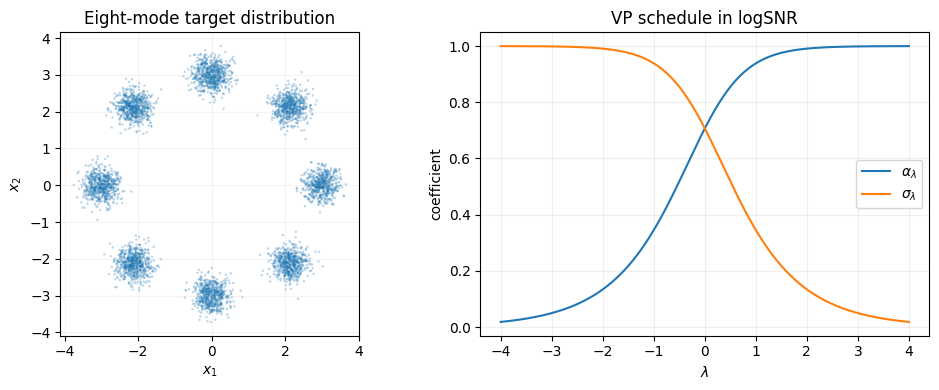

In [2]:
class VPSchedule:
    def __init__(self, lambda_min=-4.0, lambda_max=4.0):
        self.lambda_min = lambda_min
        self.lambda_max = lambda_max

    def alpha_sigma(self, lam):
        lam = tensor(lam)
        alpha = torch.sqrt(torch.sigmoid(2*lam))
        sigma = torch.sqrt(torch.sigmoid(-2*lam))
        return alpha, sigma

    def grid(self, steps):
        return torch.linspace(
            self.lambda_min, self.lambda_max, steps+1,
            device=DEVICE, dtype=DTYPE,
        )


class GaussianMixture2D:
    def __init__(self, radius=3.0, component_std=0.25, modes=8):
        angles = torch.arange(modes, device=DEVICE, dtype=DTYPE)*2*math.pi/modes
        self.means = radius*torch.stack([torch.cos(angles), torch.sin(angles)], dim=1)
        self.component_std = component_std
        self.modes = modes

    def sample(self, n):
        labels = torch.randint(self.modes, (n,), device=DEVICE)
        return self.means[labels]+self.component_std*torch.randn(
            n, 2, device=DEVICE, dtype=DTYPE
        )

    def score(self, x, lam, schedule):
        alpha, sigma = schedule.alpha_sigma(lam)
        if alpha.ndim == 0:
            variance = alpha.square()*self.component_std**2+sigma.square()
            centers = alpha*self.means
            delta = x[:, None, :]-centers[None, :, :]
            logits = -delta.square().sum(-1)/(2*variance)
            component_score = -delta/variance
        else:
            variance = alpha.square()*self.component_std**2+sigma.square()
            centers = alpha[:, None, None]*self.means[None, :, :]
            delta = x[:, None, :]-centers
            logits = -delta.square().sum(-1)/(2*variance[:, None])
            component_score = -delta/variance[:, None, None]
        responsibilities = torch.softmax(logits, dim=1)
        return (responsibilities[:, :, None]*component_score).sum(dim=1)

    def epsilon(self, x, lam, schedule):
        _, sigma = schedule.alpha_sigma(lam)
        if sigma.ndim == 1:
            sigma = sigma[:, None]
        return -sigma*self.score(x, lam, schedule)

    def data_prediction(self, x, lam, schedule):
        alpha, sigma = schedule.alpha_sigma(lam)
        if alpha.ndim == 1:
            alpha, sigma = alpha[:, None], sigma[:, None]
        return (x+sigma.square()*self.score(x, lam, schedule))/alpha


schedule = VPSchedule(lambda_min=-4.0, lambda_max=4.0)
gmm = GaussianMixture2D()

preview = gmm.sample(5_000).cpu().numpy()
lambda_grid = torch.linspace(-4, 4, 300, device=DEVICE, dtype=DTYPE)
alpha_grid, sigma_grid = schedule.alpha_sigma(lambda_grid)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(preview[:, 0], preview[:, 1], s=3, alpha=0.3, edgecolors="none")
axes[0].set(title="Eight-mode target distribution", xlabel="$x_1$", ylabel="$x_2$")
axes[0].set_aspect("equal")
axes[0].grid(alpha=0.15)
axes[1].plot(lambda_grid.cpu(), alpha_grid.cpu(), label=r"$\alpha_\lambda$")
axes[1].plot(lambda_grid.cpu(), sigma_grid.cpu(), label=r"$\sigma_\lambda$")
axes[1].set(title="VP schedule in logSNR", xlabel=r"$\lambda$", ylabel="coefficient")
axes[1].legend()
axes[1].grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"01_target_and_schedule.png", dpi=170, bbox_inches="tight")
plt.show()

## 2. 三种预测参数化与正确的 PF ODE

Score $s_\theta$、噪声预测 $\epsilon_\theta$ 与数据预测 $D_\theta$ 的转换为

$$
\epsilon_\theta=-\sigma s_\theta,
\qquad
D_\theta=\frac{x+\sigma^2s_\theta}{\alpha}
=\frac{x-\sigma\epsilon_\theta}{\alpha}.
$$

VP 概率流 ODE 在 $\lambda$ 时间下为

$$
\frac{dx}{d\lambda}=\sigma^2x-\sigma\epsilon_\theta.
$$

代入数据预测关系得到

$$
\boxed{
\frac{dx}{d\lambda}=\alpha D_\theta-\alpha^2x
=\alpha(D_\theta-\alpha x)
}.
$$

这里不能写成 $\alpha^2(D_\theta-x)$；两式一般不相等。后面的 RK4、Euler 和 Heun 都使用上面的正确速度。

In [3]:
class OracleModel:
    # Only used for analytic identities and network validation.
    def __init__(self, distribution, schedule):
        self.distribution = distribution
        self.schedule = schedule
        self.nfe = 0

    def reset(self):
        self.nfe = 0

    def predict(self, x, lam):
        self.nfe += 1
        return self.distribution.data_prediction(x, lam, self.schedule)


class DenoiserMLP(nn.Module):
    def __init__(self, hidden=160, frequencies=4):
        super().__init__()
        self.frequencies = frequencies
        time_dim = 1+2*frequencies
        self.net = nn.Sequential(
            nn.Linear(2+time_dim, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2),
        )

    def time_embedding(self, lam):
        if lam.ndim == 0:
            lam = lam.expand(1)
        normalized = lam.reshape(-1, 1)/4
        frequency = torch.arange(
            1, self.frequencies+1, device=lam.device, dtype=lam.dtype
        )[None, :]
        phase = math.pi*normalized*frequency
        return torch.cat([normalized, torch.sin(phase), torch.cos(phase)], dim=1)

    def forward(self, x, lam):
        if lam.ndim == 0:
            lam = lam.expand(len(x))
        return self.net(torch.cat([x, self.time_embedding(lam)], dim=1))


class LearnedModel:
    def __init__(self, network):
        self.network = network
        self.nfe = 0

    def reset(self):
        self.nfe = 0

    def predict(self, x, lam):
        self.nfe += 1
        return self.network(x, lam)


def ode_velocity(x, lam, model, schedule):
    alpha, _ = schedule.alpha_sigma(lam)
    data_prediction = model.predict(x, lam)
    return alpha*data_prediction-alpha.square()*x


oracle = OracleModel(gmm, schedule)

## 3. 先训练数据预测网络

训练目标是

$$
\mathcal L_D=\mathbb E
\left\|D_\theta(\alpha_\lambda x_0+\sigma_\lambda\epsilon,\lambda)-x_0\right\|^2.
$$

监督标签 $x_0$ 在低信噪比处具有不可约的后验不确定性，所以训练 loss 不应被要求趋近于零。真正需要检查的是网络是否接近解析条件均值

$$
D^*(x_\lambda,\lambda)=\mathbb E[x_0\mid x_\lambda],
$$

它可由解析 GMM Score 和 Tweedie 公式计算。后面的所有 ODE 与 SDE 采样器都使用这里训练出的同一个网络。

In [4]:
set_seed(SEED+100)
denoiser = DenoiserMLP().to(device=DEVICE, dtype=DTYPE)
optimizer = torch.optim.Adam(denoiser.parameters(), lr=1e-3)
TRAIN_STEPS = 6_000
BATCH_SIZE = 1_024
training_losses = []
training_started = time.perf_counter()

denoiser.train()
for step in range(1, TRAIN_STEPS+1):
    clean = gmm.sample(BATCH_SIZE)
    lam = torch.empty(BATCH_SIZE, device=DEVICE, dtype=DTYPE).uniform_(
        schedule.lambda_min, schedule.lambda_max
    )
    alpha = torch.sqrt(torch.sigmoid(2*lam))[:, None]
    sigma = torch.sqrt(torch.sigmoid(-2*lam))[:, None]
    noisy = alpha*clean+sigma*torch.randn_like(clean)
    prediction = denoiser(noisy, lam)
    loss = F.mse_loss(prediction, clean)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    training_losses.append(loss.item())
    if step == 1 or step % 600 == 0:
        print(f"step {step:4d}/{TRAIN_STEPS}: loss(100-step avg)={np.mean(training_losses[-100:]):.6f}")

denoiser.eval()
learned_model = LearnedModel(denoiser)
print(f"Training finished in {time.perf_counter()-training_started:.1f} s")
print(f"Trainable parameters: {sum(p.numel() for p in denoiser.parameters()):,}")
torch.save(denoiser.state_dict(), OUTPUT_DIR/"data_prediction_network.pt")

step    1/6000: loss(100-step avg)=4.591776


step  600/6000: loss(100-step avg)=1.816329


step 1200/6000: loss(100-step avg)=1.795689


step 1800/6000: loss(100-step avg)=1.807709


step 2400/6000: loss(100-step avg)=1.801183


...

step 3600/6000: loss(100-step avg)=1.801020


step 4200/6000: loss(100-step avg)=1.816210


step 4800/6000: loss(100-step avg)=1.794415


step 5400/6000: loss(100-step avg)=1.790782


step 6000/6000: loss(100-step avg)=1.790195
Training finished in 57.1 s
Trainable parameters: 53,762


Held-out MSE against noisy x0 labels : 1.781482
MSE against analytic posterior D*   : 0.004783
Zero predictor MSE against D*       : 2.787738


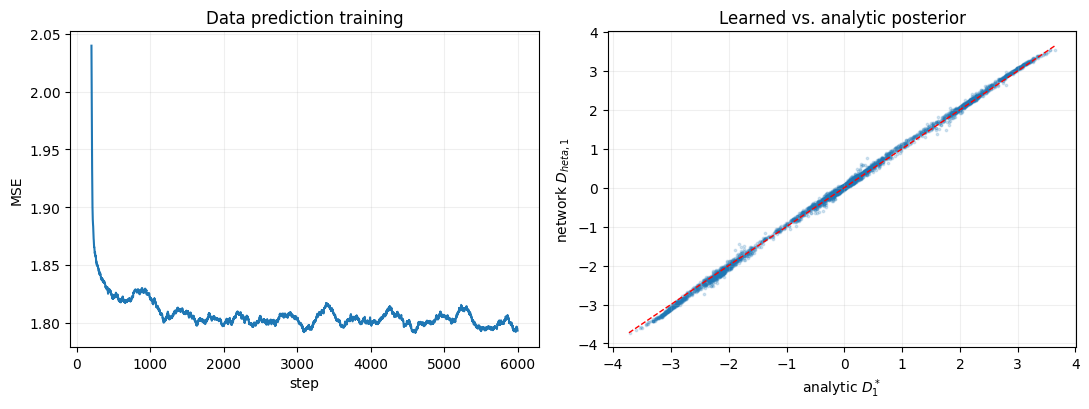

In [5]:
with torch.no_grad():
    validation_count = 20_000
    validation_clean = gmm.sample(validation_count)
    validation_lambda = torch.empty(
        validation_count, device=DEVICE, dtype=DTYPE
    ).uniform_(schedule.lambda_min, schedule.lambda_max)
    validation_alpha, validation_sigma = schedule.alpha_sigma(validation_lambda)
    validation_noisy = (
        validation_alpha[:, None]*validation_clean
        +validation_sigma[:, None]*torch.randn_like(validation_clean)
    )
    network_prediction = denoiser(validation_noisy, validation_lambda)
    analytic_posterior = gmm.data_prediction(
        validation_noisy, validation_lambda, schedule
    )
    supervised_mse = F.mse_loss(network_prediction, validation_clean).item()
    posterior_mse = F.mse_loss(network_prediction, analytic_posterior).item()
    zero_posterior_mse = analytic_posterior.square().mean().item()

print(f"Held-out MSE against noisy x0 labels : {supervised_mse:.6f}")
print(f"MSE against analytic posterior D*   : {posterior_mse:.6f}")
print(f"Zero predictor MSE against D*       : {zero_posterior_mse:.6f}")

window = 200
smoothed_loss = np.convolve(training_losses, np.ones(window)/window, mode="valid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(np.arange(window, len(training_losses)+1), smoothed_loss)
axes[0].set(title="Data prediction training", xlabel="step", ylabel="MSE")
axes[0].grid(alpha=0.2)

subset = slice(0, 4_000)
axes[1].scatter(
    analytic_posterior[subset, 0].cpu(), network_prediction[subset, 0].cpu(),
    s=3, alpha=0.18,
)
low = min(analytic_posterior[subset, 0].min(), network_prediction[subset, 0].min()).item()
high = max(analytic_posterior[subset, 0].max(), network_prediction[subset, 0].max()).item()
axes[1].plot([low, high], [low, high], "r--", lw=1)
axes[1].set(title="Learned vs. analytic posterior", xlabel="analytic $D_1^*$", ylabel="network $D_{\theta,1}$")
axes[1].grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"02_model_training.png", dpi=170, bbox_inches="tight")
plt.show()

## 4. 确定性 DPM-Solver / DPM-Solver++

DPM-Solver-1 使用噪声预测：

$$
x_t=\frac{\alpha_t}{\alpha_s}x_s
-\sigma_t(e^h-1)\epsilon_\theta(x_s,s),
\qquad h=\lambda_t-\lambda_s.
$$

DPM-Solver++1 使用数据预测：

$$
x_t=\frac{\sigma_t}{\sigma_s}x_s
+\alpha_t(1-e^{-h})D_\theta(x_s,s).
$$

DPM-Solver++(2S) 在区间中点额外计算一次模型；2M 利用上一时间点的数据预测构造二阶多步外推。实际求解器测试全部使用刚刚训练好的 `learned_model`。

In [6]:
@torch.no_grad()
def sample_ode(x_initial, model, schedule, steps, method):
    grid = schedule.grid(steps)
    x = x_initial.clone()
    model.reset()
    previous_prediction = None
    previous_h = None

    for index in range(steps):
        s, t = grid[index], grid[index+1]
        h = t-s
        alpha_s, sigma_s = schedule.alpha_sigma(s)
        alpha_t, sigma_t = schedule.alpha_sigma(t)

        if method == "euler":
            x = x+h*ode_velocity(x, s, model, schedule)
        elif method == "heun":
            velocity_s = ode_velocity(x, s, model, schedule)
            predictor = x+h*velocity_s
            velocity_t = ode_velocity(predictor, t, model, schedule)
            x = x+0.5*h*(velocity_s+velocity_t)
        elif method == "dpm1":
            data_prediction = model.predict(x, s)
            epsilon = (x-alpha_s*data_prediction)/sigma_s
            x = alpha_t/alpha_s*x-sigma_t*torch.expm1(h)*epsilon
        elif method == "dpmpp1":
            data_prediction = model.predict(x, s)
            x = sigma_t/sigma_s*x+alpha_t*(-torch.expm1(-h))*data_prediction
        elif method == "dpmpp2s":
            ratio = 0.5
            middle = s+ratio*h
            alpha_m, sigma_m = schedule.alpha_sigma(middle)
            prediction_s = model.predict(x, s)
            middle_state = (
                sigma_m/sigma_s*x
                +alpha_m*(-torch.expm1(-ratio*h))*prediction_s
            )
            prediction_m = model.predict(middle_state, middle)
            corrected_prediction = prediction_s+(prediction_m-prediction_s)/(2*ratio)
            x = sigma_t/sigma_s*x+alpha_t*(-torch.expm1(-h))*corrected_prediction
        elif method == "dpmpp2m":
            prediction_s = model.predict(x, s)
            if previous_prediction is None:
                corrected_prediction = prediction_s
            else:
                step_ratio = previous_h/h
                corrected_prediction = (
                    prediction_s+(prediction_s-previous_prediction)/(2*step_ratio)
                )
            x = sigma_t/sigma_s*x+alpha_t*(-torch.expm1(-h))*corrected_prediction
            previous_prediction = prediction_s
            previous_h = h
        else:
            raise ValueError(f"Unknown method: {method}")
    return x, model.nfe


@torch.no_grad()
def reference_rk4(x_initial, model, schedule, steps=800):
    grid = schedule.grid(steps)
    x = x_initial.clone()
    model.reset()
    for index in range(steps):
        s, t = grid[index], grid[index+1]
        h = t-s
        k1 = ode_velocity(x, s, model, schedule)
        k2 = ode_velocity(x+0.5*h*k1, s+0.5*h, model, schedule)
        k3 = ode_velocity(x+0.5*h*k2, s+0.5*h, model, schedule)
        k4 = ode_velocity(x+h*k3, t, model, schedule)
        x = x+h*(k1+2*k2+2*k3+k4)/6
    return x


def relative_error(value, reference):
    return (
        torch.linalg.vector_norm(value-reference)
        /torch.linalg.vector_norm(reference).clamp_min(1e-12)
    ).item()

## 5. SDE-DPM-Solver++

SDE-DPM-Solver++1 的一步更新为

$$
x_t=\frac{\sigma_t}{\sigma_s}e^{-h}x_s
+\alpha_t(1-e^{-2h})D_\theta(x_s,s)
+\sigma_t\sqrt{1-e^{-2h}}\,z,
\qquad z\sim\mathcal N(0,I).
$$

随机项的方差来自对确定性核的 Itô 积分。二阶多步版本沿用历史数据预测修正当前 $D_\theta$，仍保持每步一次新的网络调用。

实现公式按 DPM-Solver++ 的 midpoint 二阶多步形式书写。参考：[DPM-Solver++ 论文](https://arxiv.org/abs/2211.01095) 与 [Diffusers 的 SDE-DPM-Solver++ 实现](https://github.com/huggingface/diffusers/blob/main/src/diffusers/schedulers/scheduling_dpmsolver_multistep.py)。

In [7]:
@torch.no_grad()
def sample_sde(x_initial, model, schedule, steps, method="sde1", noises=None):
    grid = schedule.grid(steps)
    x = x_initial.clone()
    model.reset()
    previous_prediction = None
    previous_h = None
    if noises is None:
        noises = torch.randn(steps, *x.shape, device=x.device, dtype=x.dtype)

    for index in range(steps):
        s, t = grid[index], grid[index+1]
        h = t-s
        _, sigma_s = schedule.alpha_sigma(s)
        alpha_t, sigma_t = schedule.alpha_sigma(t)
        prediction_s = model.predict(x, s)
        if method == "sde1" or previous_prediction is None:
            corrected_prediction = prediction_s
        elif method == "sde2m":
            step_ratio = previous_h/h
            corrected_prediction = (
                prediction_s+(prediction_s-previous_prediction)/(2*step_ratio)
            )
        else:
            raise ValueError(method)

        decay = torch.exp(-h)
        variance_factor = -torch.expm1(-2*h)
        x = (
            sigma_t/sigma_s*decay*x
            +alpha_t*variance_factor*corrected_prediction
            +sigma_t*torch.sqrt(variance_factor)*noises[index]
        )
        previous_prediction = prediction_s
        previous_h = h
    return x, model.nfe

## 实验 1：Tweedie 公式与参数化转换

在解析 GMM 上分别计算 Score、噪声预测和数据预测，再双向转换。若实现正确，误差应接近 `float64` 的机器精度。

In [8]:
with torch.no_grad():
    test_x = torch.randn(2_048, 2, device=DEVICE, dtype=DTYPE)
    test_lambda = tensor(0.7)
    alpha, sigma = schedule.alpha_sigma(test_lambda)
    exact_score = gmm.score(test_x, test_lambda, schedule)
    exact_epsilon = gmm.epsilon(test_x, test_lambda, schedule)
    exact_data = gmm.data_prediction(test_x, test_lambda, schedule)

    epsilon_from_data = (test_x-alpha*exact_data)/sigma
    data_from_score = (test_x+sigma.square()*exact_score)/alpha
    score_from_data = (alpha*exact_data-test_x)/sigma.square()

    parameterization_errors = {
        "epsilon from data": (exact_epsilon-epsilon_from_data).abs().max().item(),
        "data from score": (exact_data-data_from_score).abs().max().item(),
        "score from data": (exact_score-score_from_data).abs().max().item(),
    }
for name, value in parameterization_errors.items():
    report(name, value)

epsilon from data                             : 1.33226763e-15
data from score                               : 0.00000000e+00
score from data                               : 2.66453526e-15


## 实验 2：DDIM、DPM-Solver-1 与 DPM-Solver++1

对同一个起点和时间区间，使用一致的解析模型计算三种一步更新。它们只是同一更新在噪声预测与数据预测空间中的不同写法，因此结果应在浮点误差范围内一致。

In [9]:
with torch.no_grad():
    test_x = torch.randn(2_048, 2, device=DEVICE, dtype=DTYPE)
    lambda_s, lambda_t = tensor(-1.0), tensor(-0.6)
    h = lambda_t-lambda_s
    alpha_s, sigma_s = schedule.alpha_sigma(lambda_s)
    alpha_t, sigma_t = schedule.alpha_sigma(lambda_t)
    epsilon_s = gmm.epsilon(test_x, lambda_s, schedule)
    data_s = gmm.data_prediction(test_x, lambda_s, schedule)

    ddim = alpha_t*data_s+sigma_t*epsilon_s
    dpm1 = alpha_t/alpha_s*test_x-sigma_t*torch.expm1(h)*epsilon_s
    dpmpp1 = sigma_t/sigma_s*test_x+alpha_t*(-torch.expm1(-h))*data_s

    report("DDIM vs DPM-Solver-1", (ddim-dpm1).abs().max().item())
    report("DDIM vs DPM-Solver++1", (ddim-dpmpp1).abs().max().item())

DDIM vs DPM-Solver-1                          : 8.88178420e-16
DDIM vs DPM-Solver++1                         : 8.88178420e-16


## 实验 3：训练模型上的确定性求解器精度

从同一批初始噪声出发，用训练网络的 600 步 RK4 作为数值参考，再比较 Euler、Heun、DPM-Solver-1、DPM-Solver++1/2S/2M。横轴使用 NFE，因为 2S 和 Heun 每个外层步需要两次网络调用。

这里的相对误差衡量同一个学习 ODE 的离散误差；它不包含网络相对真实分布的模型误差。

method         steps     NFE    relative error
euler              5       5     1.1515440e-01
euler             10      10     4.6269075e-02
euler             20      20     2.2434497e-02


euler             40      40     1.1551918e-02
euler             80      80     6.1605490e-03


heun               5      10     3.0579892e-02
heun              10      20     1.2940563e-02
heun              20      40     5.0742844e-03


heun              40      80     1.8316057e-03


heun              80     160     5.6115281e-04
dpm1               5       5     1.9206076e-01
dpm1              10      10     9.3025752e-02
dpm1              20      20     4.6202519e-02
dpm1              40      40     2.3134082e-02


dpm1              80      80     1.1821650e-02
dpmpp1             5       5     1.9206076e-01
dpmpp1            10      10     9.3025752e-02
dpmpp1            20      20     4.6202519e-02
dpmpp1            40      40     2.3134082e-02


dpmpp1            80      80     1.1821650e-02
dpmpp2s            5      10     5.9397315e-02
dpmpp2s           10      20     2.0660101e-02
dpmpp2s           20      40     7.1781423e-03


dpmpp2s           40      80     2.5289346e-03


dpmpp2s           80     160     7.9177549e-04
dpmpp2m            5       5     1.2306429e-01
dpmpp2m           10      10     3.2569760e-02
dpmpp2m           20      20     9.2788976e-03
dpmpp2m           40      40     3.6691994e-03


dpmpp2m           80      80     1.2828058e-03


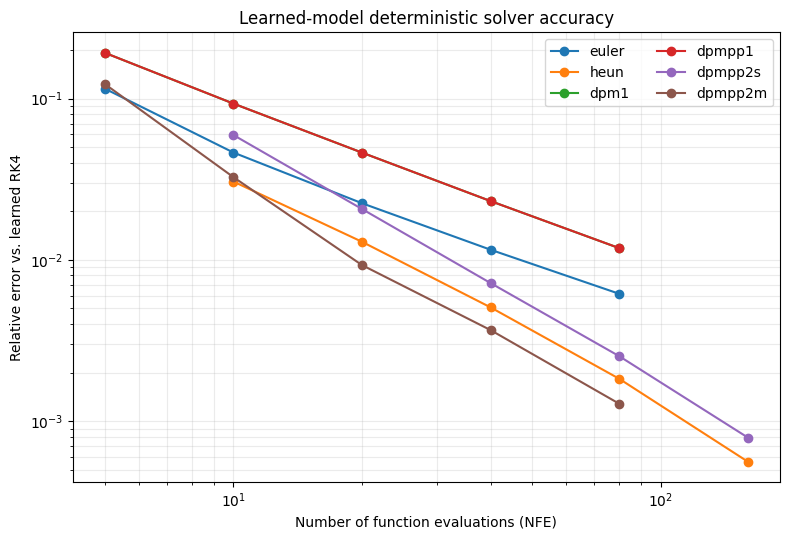

In [10]:
with torch.no_grad():
    accuracy_initial = torch.randn(800, 2, device=DEVICE, dtype=DTYPE)
    accuracy_reference = reference_rk4(
        accuracy_initial, learned_model, schedule, steps=600
    )
    deterministic_methods = ["euler", "heun", "dpm1", "dpmpp1", "dpmpp2s", "dpmpp2m"]
    step_counts = [5, 10, 20, 40, 80]
    ode_accuracy = {}

    print(f"{'method':<12} {'steps':>7} {'NFE':>7} {'relative error':>17}")
    for method in deterministic_methods:
        ode_accuracy[method] = []
        for steps in step_counts:
            output, nfe = sample_ode(
                accuracy_initial, learned_model, schedule, steps, method
            )
            error = relative_error(output, accuracy_reference)
            ode_accuracy[method].append((steps, nfe, error))
            print(f"{method:<12} {steps:7d} {nfe:7d} {error:17.7e}")

fig, ax = plt.subplots(figsize=(8, 5.5))
for method, rows in ode_accuracy.items():
    ax.loglog([row[1] for row in rows], [row[2] for row in rows], "o-", label=method)
ax.set(xlabel="Number of function evaluations (NFE)", ylabel="Relative error vs. learned RK4",
       title="Learned-model deterministic solver accuracy")
ax.grid(True, which="both", alpha=0.25)
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"03_learned_ode_accuracy.png", dpi=170, bbox_inches="tight")
plt.show()

## 实验 4：训练模型上的确定性生成

相对 RK4 的误差只说明数值求解是否准确。下面再将 20 步生成样本与真实八模态分布比较，报告多尺度 RBF MMD。所有求解器使用同一个训练网络和同一批初始噪声。

euler      NFE=20  MMD2=0.0099531
heun       NFE=40  MMD2=0.0095424


dpmpp1     NFE=20  MMD2=0.0076583
dpmpp2s    NFE=40  MMD2=0.0094156


dpmpp2m    NFE=20  MMD2=0.0097197


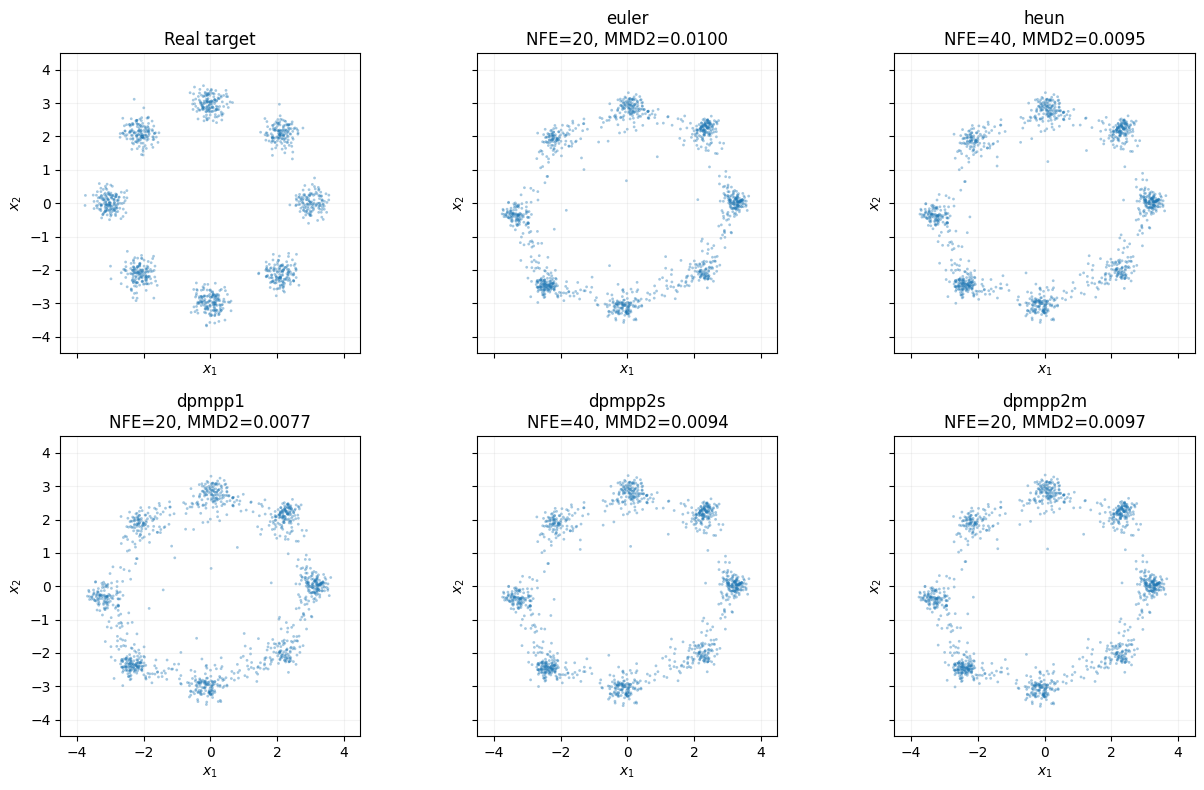

In [11]:
@torch.no_grad()
def mmd2(x, y, bandwidths=(0.25, 1.0, 4.0, 16.0)):
    xx = torch.cdist(x, x).square()
    yy = torch.cdist(y, y).square()
    xy = torch.cdist(x, y).square()
    value = 0.0
    for bandwidth in bandwidths:
        value += (
            torch.exp(-xx/(2*bandwidth)).mean()
            +torch.exp(-yy/(2*bandwidth)).mean()
            -2*torch.exp(-xy/(2*bandwidth)).mean()
        )
    return max(0.0, float(value/len(bandwidths)))


with torch.no_grad():
    generation_count = 1_200
    real_samples = gmm.sample(generation_count)
    generation_initial = torch.randn(generation_count, 2, device=DEVICE, dtype=DTYPE)
    generation_methods = ["euler", "heun", "dpmpp1", "dpmpp2s", "dpmpp2m"]
    generated_samples = {}
    generation_metrics = {}
    for method in generation_methods:
        output, nfe = sample_ode(
            generation_initial, learned_model, schedule, 20, method
        )
        score = mmd2(output, real_samples)
        generated_samples[method] = output.cpu().numpy()
        generation_metrics[method] = (nfe, score)
        print(f"{method:<10} NFE={nfe:<3d} MMD2={score:.7f}")

fig, axes = plt.subplots(2, 3, figsize=(13, 8), sharex=True, sharey=True)
panels = [("Real target", real_samples.cpu().numpy())]+[
    (f"{method}\nNFE={generation_metrics[method][0]}, MMD2={generation_metrics[method][1]:.4f}",
     generated_samples[method])
    for method in generation_methods
]
for ax, (title, points) in zip(axes.ravel(), panels):
    ax.scatter(points[:, 0], points[:, 1], s=4, alpha=0.4, edgecolors="none")
    ax.set(title=title, xlim=(-4.5, 4.5), ylim=(-4.5, 4.5), xlabel="$x_1$", ylabel="$x_2$")
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"04_learned_ode_generation.png", dpi=170, bbox_inches="tight")
plt.show()

## 实验 5：SDE-DPM-Solver++1 与随机 DDIM

把同一个数据预测和同一个高斯噪声代入两种公式。特定噪声标准差下，随机 DDIM 可以重写为 SDE-DPM-Solver++1；最大差异应接近机器精度。

In [12]:
with torch.no_grad():
    test_x = torch.randn(2_048, 2, device=DEVICE, dtype=DTYPE)
    shared_noise = torch.randn_like(test_x)
    lambda_s, lambda_t = tensor(-1.0), tensor(-0.5)
    h = lambda_t-lambda_s
    alpha_s, sigma_s = schedule.alpha_sigma(lambda_s)
    alpha_t, sigma_t = schedule.alpha_sigma(lambda_t)
    data_s = gmm.data_prediction(test_x, lambda_s, schedule)
    epsilon_s = (test_x-alpha_s*data_s)/sigma_s
    noise_std = sigma_t*torch.sqrt(-torch.expm1(-2*h))

    sde_update = (
        sigma_t/sigma_s*torch.exp(-h)*test_x
        +alpha_t*(-torch.expm1(-2*h))*data_s
        +noise_std*shared_noise
    )
    stochastic_ddim = (
        alpha_t*data_s
        +torch.sqrt(sigma_t.square()-noise_std.square())*epsilon_s
        +noise_std*shared_noise
    )
    report("SDE-DPM++1 vs stochastic DDIM", (sde_update-stochastic_ddim).abs().max().item())

SDE-DPM++1 vs stochastic DDIM                 : 8.88178420e-16


## 实验 6：随机指数积分的高斯性

SDE 精确积分中的随机项为

$$
I=\sqrt{2}\,\sigma_t
\int_{\lambda_s}^{\lambda_t}e^{-(\lambda_t-u)}dW_u.
$$

因为被积核是确定性的，$I$ 是零均值高斯变量，方差为

$$
\operatorname{Var}(I)=\sigma_t^2(1-e^{-2h}).
$$

下面直接离散 Itô 积分，比较经验直方图、解析密度和方差。

Ito theoretical mean                          : 0.00000000e+00
Ito empirical mean                            : 3.92455892e-03
Ito theoretical variance                      : 4.32332358e-01
Ito empirical variance                        : 4.22792988e-01


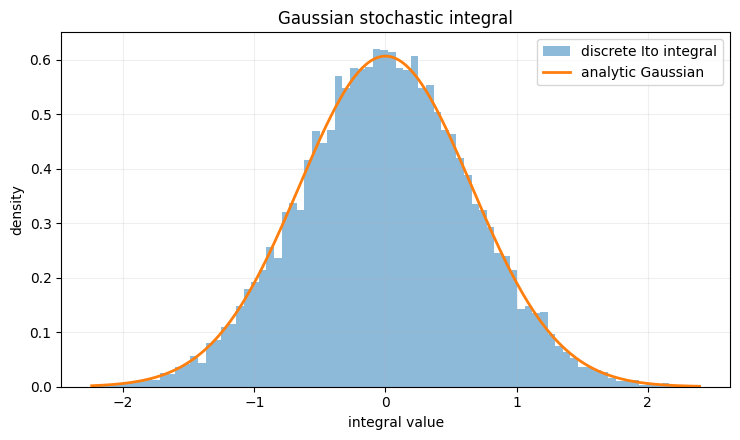

In [13]:
with torch.no_grad():
    lambda_s, lambda_t = -1.0, 0.0
    h = lambda_t-lambda_s
    _, sigma_t = schedule.alpha_sigma(lambda_t)
    ito_grid_size = 200
    ito_samples = 20_000
    integration_grid = torch.linspace(
        lambda_s, lambda_t, ito_grid_size+1, device=DEVICE, dtype=DTYPE
    )
    du = integration_grid[1]-integration_grid[0]
    kernel = torch.exp(-(lambda_t-integration_grid[:-1]))
    brownian_increment = torch.randn(
        ito_samples, ito_grid_size, device=DEVICE, dtype=DTYPE
    )*torch.sqrt(du)
    integral = math.sqrt(2)*sigma_t*(brownian_increment*kernel[None, :]).sum(dim=1)
    theoretical_variance = (sigma_t.square()*(1-math.exp(-2*h))).item()
    empirical_mean = integral.mean().item()
    empirical_variance = integral.var(unbiased=True).item()
    report("Ito theoretical mean", 0.0)
    report("Ito empirical mean", empirical_mean)
    report("Ito theoretical variance", theoretical_variance)
    report("Ito empirical variance", empirical_variance)

values = integral.cpu().numpy()
x_axis = np.linspace(values.min(), values.max(), 320)
normal_density = np.exp(-x_axis**2/(2*theoretical_variance))/math.sqrt(2*math.pi*theoretical_variance)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.hist(values, bins=80, density=True, alpha=0.5, label="discrete Ito integral")
ax.plot(x_axis, normal_density, lw=2, label="analytic Gaussian")
ax.set(title="Gaussian stochastic integral", xlabel="integral value", ylabel="density")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"04_ito_gaussian.png", dpi=170, bbox_inches="tight")
plt.show()

## 实验 7：训练模型上的 SDE-DPM-Solver++（含 Oracle 诊断）

这一实验仍以训练得到的 `learned_model` 为主体，并加入解析 `oracle_model` 作为**诊断对照**。两者使用完全相同的初始噪声、目标样本和逐步高斯增量：

- 左图回答实际问题：训练网络接入 ODE / SDE 求解器后，生成质量怎样；
- 右图隔离网络误差：当数据预测完全准确时，求解器本身怎样收敛。

每个设置独立重复 3 次并报告 MMD 均值与标准差。SDE1 与 SDE2M 在同一次重复中共享全部随机增量，避免随机数差异掩盖求解器差异。SDE2M 使用官方 midpoint 形式

$$
D_0=D_\theta(x_s,s),\qquad
D_1=\frac{D_0-D_{\mathrm{prev}}}{r},\qquad
\widetilde D=D_0+\frac12D_1,
$$

其中 $r=h_{\mathrm{prev}}/h$。第一步没有历史量，按一阶公式启动。

trained ode2m   steps=5   MMD2=0.0192709 +/- 0.0012853
trained sde1    steps=5   MMD2=0.0206750 +/- 0.0012176
trained sde2m   steps=5   MMD2=0.0328011 +/- 0.0015824
oracle  ode2m   steps=5   MMD2=0.0154540 +/- 0.0003083
oracle  sde1    steps=5   MMD2=0.0151192 +/- 0.0006737
oracle  sde2m   steps=5   MMD2=0.0319060 +/- 0.0009065


trained ode2m   steps=10  MMD2=0.0087169 +/- 0.0015554
trained sde1    steps=10  MMD2=0.0070780 +/- 0.0008289
trained sde2m   steps=10  MMD2=0.0147322 +/- 0.0004605
oracle  ode2m   steps=10  MMD2=0.0021066 +/- 0.0003259
oracle  sde1    steps=10  MMD2=0.0029860 +/- 0.0003153
oracle  sde2m   steps=10  MMD2=0.0034583 +/- 0.0003061


trained ode2m   steps=20  MMD2=0.0088320 +/- 0.0008370
trained sde1    steps=20  MMD2=0.0107384 +/- 0.0007148
trained sde2m   steps=20  MMD2=0.0156872 +/- 0.0006492
oracle  ode2m   steps=20  MMD2=0.0020943 +/- 0.0004965
oracle  sde1    steps=20  MMD2=0.0018547 +/- 0.0004690
oracle  sde2m   steps=20  MMD2=0.0018133 +/- 0.0004318


trained ode2m   steps=40  MMD2=0.0084467 +/- 0.0005937
trained sde1    steps=40  MMD2=0.0123320 +/- 0.0016033
trained sde2m   steps=40  MMD2=0.0152854 +/- 0.0018400
oracle  ode2m   steps=40  MMD2=0.0013511 +/- 0.0004410
oracle  sde1    steps=40  MMD2=0.0011450 +/- 0.0004387
oracle  sde2m   steps=40  MMD2=0.0011780 +/- 0.0004188


trained ode2m   steps=80  MMD2=0.0071358 +/- 0.0004484
trained sde1    steps=80  MMD2=0.0137270 +/- 0.0003331
trained sde2m   steps=80  MMD2=0.0154389 +/- 0.0004850
oracle  ode2m   steps=80  MMD2=0.0013064 +/- 0.0003425
oracle  sde1    steps=80  MMD2=0.0008759 +/- 0.0002232
oracle  sde2m   steps=80  MMD2=0.0008593 +/- 0.0002674


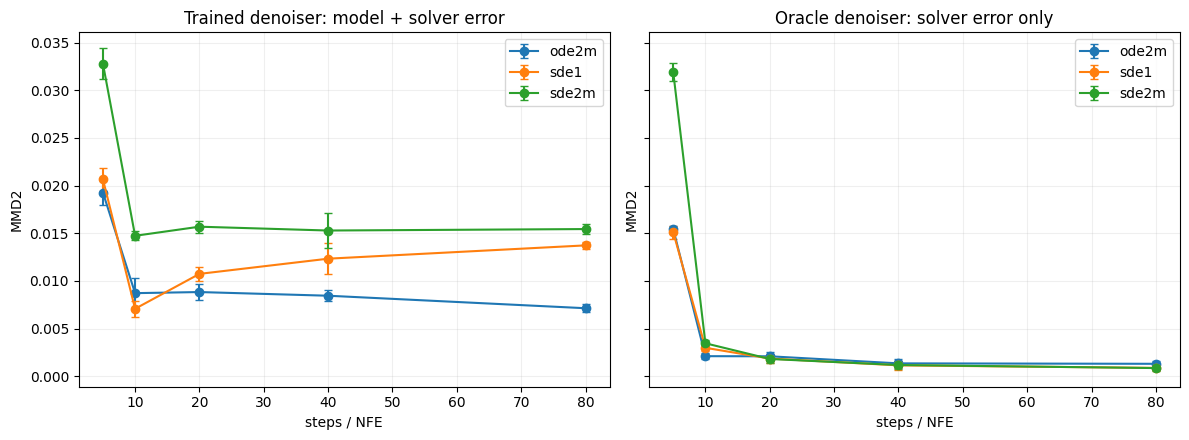

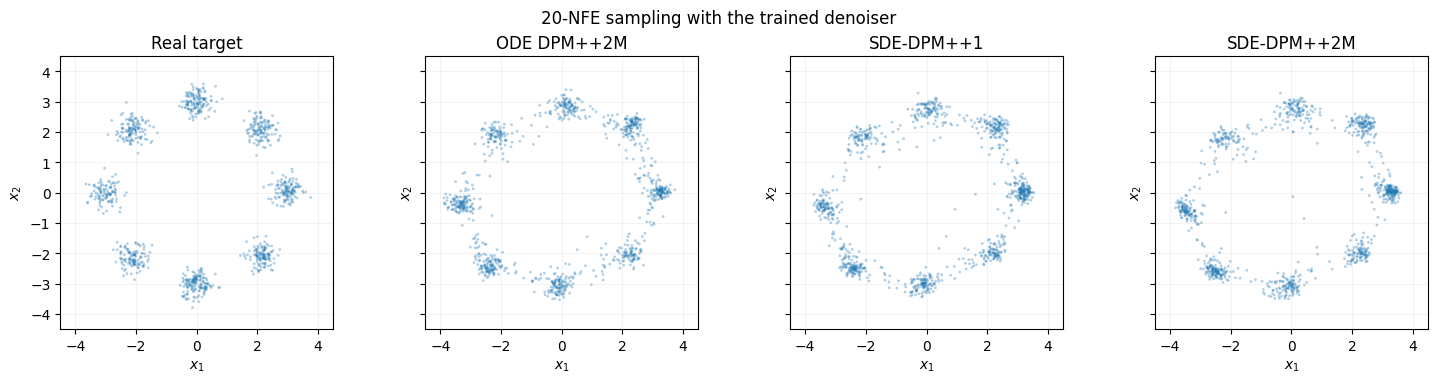

In [14]:
with torch.no_grad():
    sde_count = 1_000
    sde_steps = [5, 10, 20, 40, 80]
    repetitions = 3
    compared_models = {
        "trained": learned_model,
        "oracle": oracle,
    }
    method_names = ["ode2m", "sde1", "sde2m"]
    sde_metrics = {
        model_name: {method: [] for method in method_names}
        for model_name in compared_models
    }
    sde_visual = {}

    for steps in sde_steps:
        repeated_scores = {
            model_name: {method: [] for method in method_names}
            for model_name in compared_models
        }
        for repetition in range(repetitions):
            comparison_real = gmm.sample(sde_count)
            comparison_initial = torch.randn(
                sde_count, 2, device=DEVICE, dtype=DTYPE
            )
            shared_noises = torch.randn(
                steps, sde_count, 2, device=DEVICE, dtype=DTYPE
            )

            for model_name, current_model in compared_models.items():
                ode_output, _ = sample_ode(
                    comparison_initial, current_model, schedule, steps, "dpmpp2m"
                )
                repeated_scores[model_name]["ode2m"].append(
                    mmd2(ode_output, comparison_real)
                )
                for method in ["sde1", "sde2m"]:
                    output, _ = sample_sde(
                        comparison_initial, current_model, schedule, steps,
                        method=method, noises=shared_noises,
                    )
                    repeated_scores[model_name][method].append(
                        mmd2(output, comparison_real)
                    )
                    if model_name == "trained" and steps == 20 and repetition == 0:
                        sde_visual[method] = output.cpu().numpy()
                if model_name == "trained" and steps == 20 and repetition == 0:
                    sde_visual["ode2m"] = ode_output.cpu().numpy()
                    sde_visual["real"] = comparison_real.cpu().numpy()

        for model_name in compared_models:
            for method in method_names:
                values = repeated_scores[model_name][method]
                mean_score = float(np.mean(values))
                std_score = float(np.std(values))
                sde_metrics[model_name][method].append((mean_score, std_score))
                print(
                    f"{model_name:<7} {method:<7} steps={steps:<3d} "
                    f"MMD2={mean_score:.7f} +/- {std_score:.7f}"
                )

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, model_name, title in zip(
    axes,
    ["trained", "oracle"],
    ["Trained denoiser: model + solver error", "Oracle denoiser: solver error only"],
):
    for method, rows in sde_metrics[model_name].items():
        means = [row[0] for row in rows]
        standard_deviations = [row[1] for row in rows]
        ax.errorbar(
            sde_steps, means, yerr=standard_deviations,
            marker="o", capsize=3, label=method,
        )
    ax.set(title=title, xlabel="steps / NFE", ylabel="MMD2")
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"07_trained_vs_oracle_sde_comparison.png", dpi=170, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.7), sharex=True, sharey=True)
for ax, key, title in zip(
    axes,
    ["real", "ode2m", "sde1", "sde2m"],
    ["Real target", "ODE DPM++2M", "SDE-DPM++1", "SDE-DPM++2M"],
):
    points = sde_visual[key]
    ax.scatter(points[:, 0], points[:, 1], s=4, alpha=0.35, edgecolors="none")
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", xlim=(-4.5, 4.5), ylim=(-4.5, 4.5))
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)
fig.suptitle("20-NFE sampling with the trained denoiser")
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"08_trained_model_sde_samples.png", dpi=170, bbox_inches="tight")
plt.show()

## 8. 结果解读

1. **先训练，再统一测试**：确定性 ODE 和随机 SDE 求解器都使用第 3 节训练的同一个 $D_\theta$。训练目标、后验验收、求解器和最终生成构成一条完整实验链。
2. **区分网络误差与离散误差**：训练模型相对 600 步 RK4 的误差主要衡量 ODE 离散误差；与真实数据的 MMD 同时包含网络近似误差、有限步误差和有限样本波动。
3. **Oracle 是诊断工具**：Oracle 曲线只用于检查公式与求解器阶数。若二阶方法在 Oracle 下改善、在训练模型下没有改善，说明历史预测外推放大了网络误差；这不应被误写成“二阶一定更好”。
4. **SDE 已用训练模型完整测试**：SDE-DPM-Solver++1/2M 与确定性 2M 使用相同初始样本；两个 SDE 方法还共享逐步随机增量，并通过 3 次重复报告 MMD 波动。
5. **SDE 更新不是给 ODE 随意加噪声**：漂移系数与噪声方差来自同一个随机指数积分。实验 5 检查随机 DDIM 的等价形式，实验 6 单独检查 Itô 积分方差。

这个二维 toy 实验没有覆盖图像模型中的 CFG 和 Dynamic Thresholding；当前范围集中验证“训练网络 $\rightarrow$ ODE/SDE 求解器 $\rightarrow$ 分布质量”的完整流程。